In [1]:
import numpy as np
import model
from multiregion import multiregion_model
import matplotlib.pyplot as plt

In [2]:
##2024 data
# Skåne county population  1,421,781
# Stockholm county population 2,473,307

## Total 2024 year internal migration
# Skåne to Stockholm 5,300
# Stockholm to Skåne 5,682

## Skane region 1
## Stockholm region 2
## Daily movement ratios
w12 = 5682/(365*2473307)
w21 = 5300/(365*1421781)
W = np.array([[0,w12],[w21,0]])

In [5]:
W

array([[0.00000000e+00, 6.29405217e-06],
       [1.02129287e-05, 0.00000000e+00]])

Simulate an outrbeak in Stockholm, keep Skane clean

Same epidemic parameters for both cities

In [6]:
region1 = model.model(sigma=8,T=0.04,N=1421781,gamma=0.0,alpha=0.04,initial_status=[1421781,0,0])
region2 = model.model(sigma=8,T=0.04,N=2473307,gamma=0.0,alpha=0.04,initial_status=[2473300,7,0])

In [7]:
multiregion = multiregion_model([region1,region2],"mobility_SIR",mobility_weights=W)

In [17]:
t,status = multiregion.euler_solver(delta_t=0.2,T_max=90)

100%|██████████| 449/449 [00:00<00:00, 26103.21it/s]


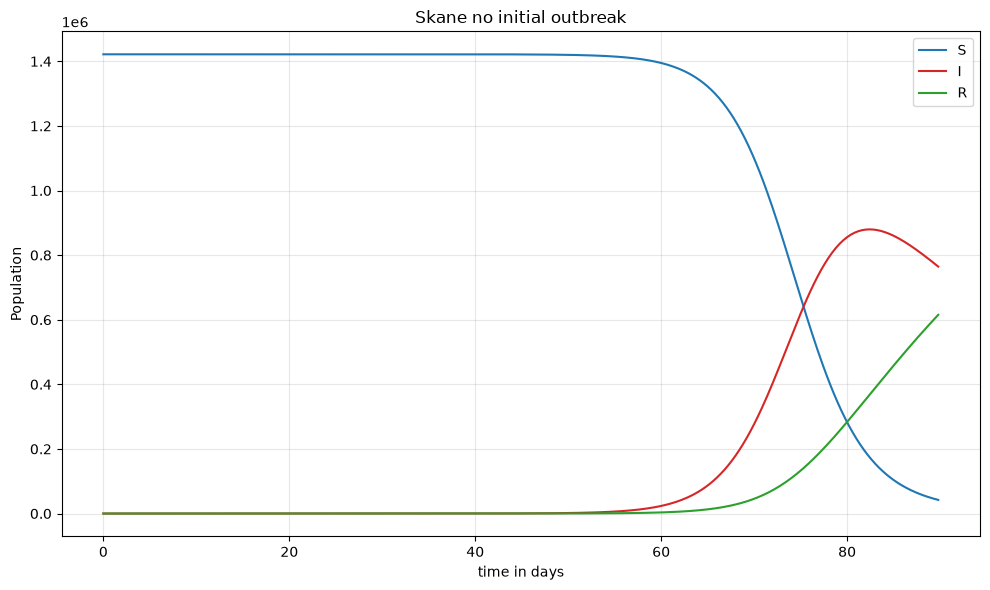

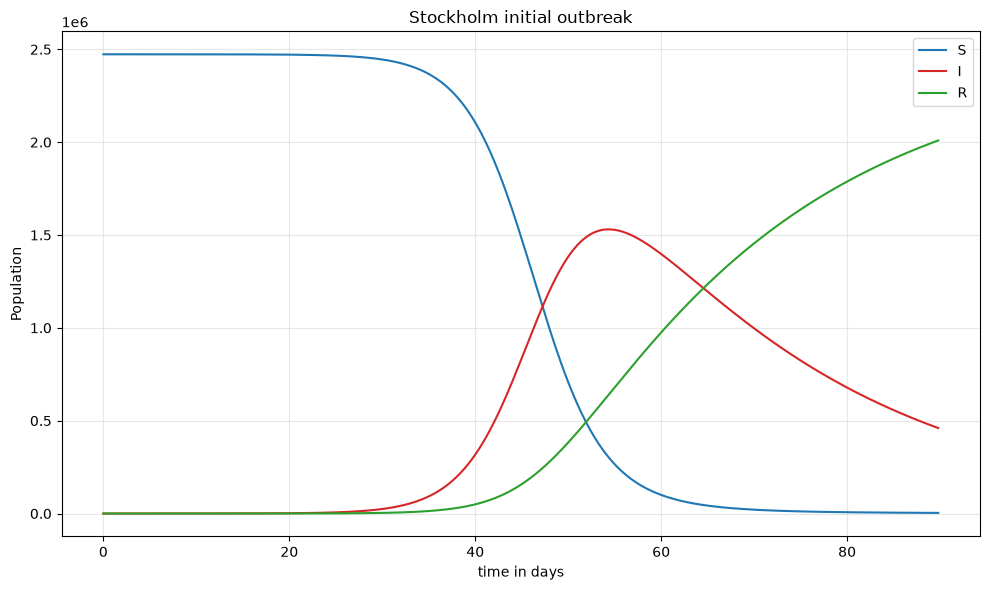

In [18]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, S, label="S", color="tab:blue")
ax.plot(t, I, label="I", color="tab:red")
ax.plot(t, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.title("Skane no initial outbreak")
plt.tight_layout()
plt.show()


S = status[:,1, 0]
I = status[:,1, 1]
R = status[:,1, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, S, label="S", color="tab:blue")
ax.plot(t, I, label="I", color="tab:red")
ax.plot(t, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.title(f"Stockholm initial outbreak")
plt.tight_layout()
plt.show()

Balance in population is as expected, overall balance +380 persons to skane and -380 to stockholm per year, as the simulation is run for 90 is almost neligible



With this parameters, mobility does not produce a noticeable change in epidemic dynamics, however there is an outbreak with aprox 1 month time shift!
